In [1]:
import torch
import random
import math

In [2]:
torch.Tensor([2.0]).double().dtype

torch.float64

In [3]:
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [4]:
# Now, let's see how micro-grad is built. It is essentially this class - which is
# the heart of the 'neural network'.
class Value:
    def __init__(self, data, _children = (), _op = '', label = ''):
        self.data = data
        self._prev = set(_children) # who are the children of this operation?
        self._op = _op # what is the operation?
        self.label = label # for the graph
        self.grad = 0

        self._backward = lambda: None
        '''
        the backward function basically does the derivative for us - it is implemented
        differently for different operations below. 
        '''

    def __repr__(self):
        '''Python uses this class to print the value it holds for data'''
        return f"data value = ({self.data})"

    def __add__(self, other):
        ''' custom implementation of addition'''
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
        
    def __mul__(self, other):
        ''' custom implementation of multiplication'''
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other):
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supports int / float"
        out = Value(self.data**other, (self, ), f'**{other}')
        
        def _backward():
            self.grad = (other * self.data ** (other - 1)) * out.grad
        out._backward = _backward

        return out

    def __truediv__(self, other):
        return self * other**-1

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        
        def _backward():
            self.grad = out.data * out.grad
        out._backward = _backward

        return out

    def __radd__(self, other):
        return self + other

    
    def tanh(self):
        '''
        The tanh function is an activation function. It is responsible to squash
        the final value into an output between -1 and 1.
        '''
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ),'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def __neg__(self):
        return self * -1
        
    def __sub__(self, other):
        return self + (-other)
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


In [5]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))
    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
  
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]
  
  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
      return [p for neuron in self.neurons for p in neuron.parameters()]
      # params = []
      # for neuron in self.neurons:
      #     ps = neuron.parameters()
      #     params.extend(ps)
      # return params

class MLP:
  
  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
      return [p for layer in self.layers for p in layer.parameters()]
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])
n(x)

len(n.parameters())

41

In [6]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

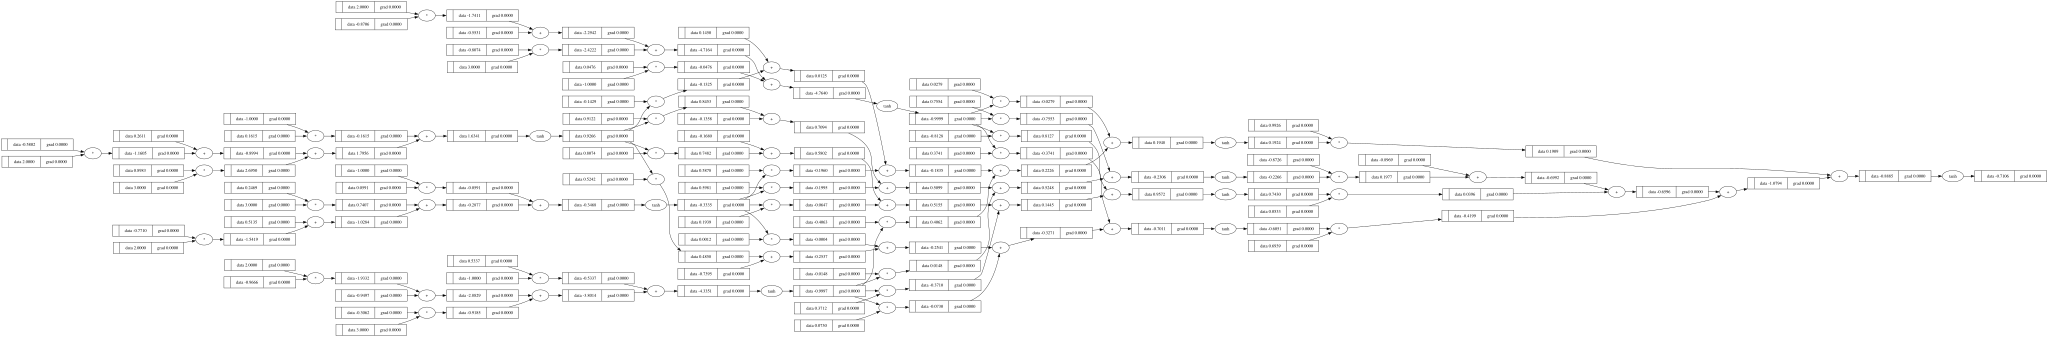

In [9]:
draw_dot(n(x))

In [10]:


xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets


In [11]:
ypred = [n(x) for x in xs]
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

data value = (5.488005599111226)

In [12]:
loss.backward()

In [13]:
for p in n.parameters():
    p.data += -0.01 * p.grad

In [14]:
ypred

[data value = (-0.7106472956655553),
 data value = (-0.556225257723215),
 data value = (-0.7025192127755909),
 data value = (-0.508728135978403)]

In [15]:
# this is known as minimizing the loss, or gradient-descent
for k in range(100):

    #forward pass
    ypred = [n(x) for x in xs]

    #calculate loss
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update parameters
    for p in n.parameters():
        p.data += -0.05 * p.grad
        

    print(k, loss.data)

0 4.602438074087398
1 3.3613065726766287
2 2.802867961851992
3 2.5702099489391745
4 2.2675347057898168
5 2.185608494366605
6 1.799718194855442
7 1.8405153506380132
8 1.2332766511777207
9 1.0080351697333216
10 0.6680209708067479
11 0.5270436589236406
12 0.44673762120843075
13 0.38890232872360214
14 0.3422400168779314
15 0.30396735182245344
16 0.27220708894458695
17 0.24556570606230219
18 0.22299609996468933
19 0.20370188979127016
20 0.18707022995341807
21 0.17262418704013888
22 0.15998862652804793
23 0.14886550824772066
24 0.13901579843700326
25 0.13024608307966357
26 0.1223985569145775
27 0.11534346166894627
28 0.10897331950648484
29 0.10319849533436083
30 0.09794375211172424
31 0.09314555494021469
32 0.0887499446877141
33 0.08471084839709077
34 0.0809887273188339
35 0.07754948788214489
36 0.07436359890775265
37 0.07140537169563717
38 0.06865236957659784
39 0.06608492100867494
40 0.06368571597847003
41 0.06143946980215098
42 0.05933264175168734
43 0.057353198507560835
44 0.055490414443

In [16]:
ypred

[data value = (0.9669882124563227),
 data value = (-0.9243112562507136),
 data value = (-0.918470233089255),
 data value = (0.9284787494741146)]